# Olist E-Commerce: Sales, Delivery & Customer Analysis

**Business context.** Olist is a Brazilian marketplace that connects small sellers to large
online stores. This analysis covers **~99K orders (Sep 2016 – Oct 2018)** across 9 linked tables.

**Questions answered**
1. How fast is the business growing, and where does revenue come from?
2. Which regions and product categories perform best — and worst?
3. How much does delivery performance drive customer satisfaction?
4. How concentrated is revenue among sellers?
5. Do customers come back? Which customer segments matter most?
6. What should the business do next?

> All monetary values are in Brazilian reais (R$). Trend charts use Jan 2017 – Aug 2018, the
> months with complete data.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from viz_style import (BLUE, ORANGE, INK, INK_2, MUTED, DIVERGING, SEQ_BLUE,
                       apply_style, money, subtitle)

apply_style()
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)
con = duckdb.connect(str(ROOT / "data" / "olist.duckdb"), read_only=True)

def sql(name: str) -> pd.DataFrame:
    """Run one of the numbered SQL files in /sql and return a DataFrame."""
    path = next((ROOT / "sql").glob(f"{name}*.sql"))
    return con.execute(path.read_text()).df()

pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Data quality checks
Before analysing, confirm the data is complete and consistent.

In [2]:
checks = con.execute("""
SELECT 'orders'                          AS check_name, COUNT(*) AS value FROM orders
UNION ALL SELECT 'duplicate order_ids',  COUNT(*) - COUNT(DISTINCT order_id) FROM orders
UNION ALL SELECT 'orders without items', COUNT(*) FROM fct_orders WHERE item_count IS NULL
UNION ALL SELECT 'orders without payment', COUNT(*) FROM fct_orders WHERE payment_value IS NULL
UNION ALL SELECT 'delivered but no delivery date', COUNT(*) FROM orders
          WHERE order_status = 'delivered' AND delivered_at IS NULL
UNION ALL SELECT 'orders without review', COUNT(*) FROM fct_orders WHERE review_score IS NULL
UNION ALL SELECT 'products without category', COUNT(*) FROM products WHERE category = 'unknown'
UNION ALL SELECT 'duplicate reviews removed', (SELECT COUNT(*) FROM raw_reviews) - (SELECT COUNT(*) FROM reviews)
""").df()
checks

,check_name,value
0,orders,99441
1,duplicate order_ids,0
2,orders without items,775
3,orders without payment,4
4,delivered but no delivery date,8
5,orders without review,768
6,products without category,610
7,duplicate reviews removed,551


**Takeaway:** the data is clean enough to analyse. Gaps are small (<1% of orders without items,
~1% without reviews, ~2% of products uncategorised) and were handled in `build_database.py`:
duplicate reviews were removed and Portuguese category names were translated to English.

## 2. Headline KPIs

In [3]:
kpis = sql('01'); kpis.T.rename(columns={0: 'value'})

,value
total_orders,"98,207.00"
unique_customers,"94,990.00"
total_revenue,"15,739,137.01"
avg_order_value,160.27
avg_items_per_order,1.14
avg_review_score,4.12
late_delivery_pct,8.11
avg_delivery_days,12.50


## 3. Sales growth

Jan–Aug revenue: 2017 R$3,575,957 -> 2018 R$8,594,666 (+140%)


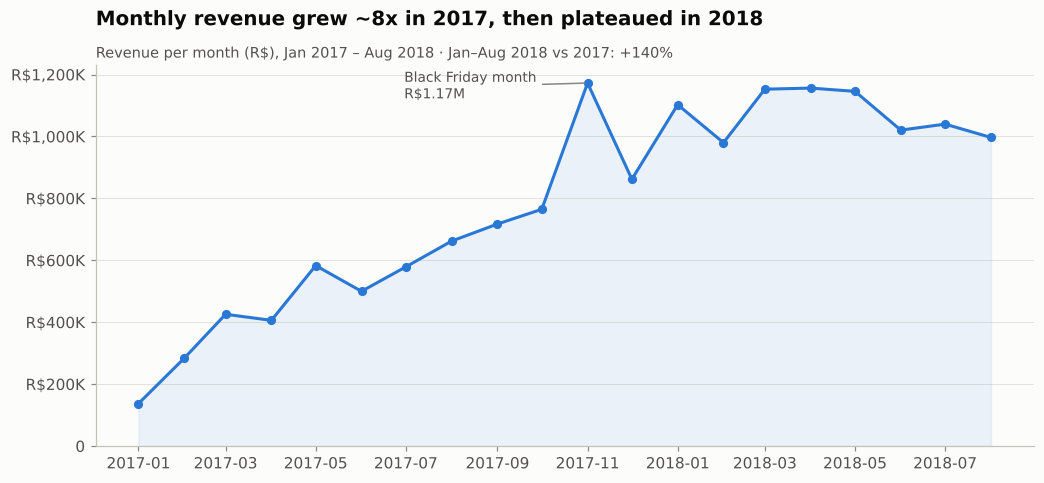

In [4]:
monthly = sql('02')
yoy = sql('03').set_index('year')
growth = yoy.loc[2018, 'revenue'] / yoy.loc[2017, 'revenue'] - 1
print(f"Jan–Aug revenue: 2017 R${yoy.loc[2017,'revenue']:,.0f} -> 2018 R${yoy.loc[2018,'revenue']:,.0f} ({growth:+.0%})")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.order_month, monthly.revenue, color=BLUE, marker="o", markersize=5)
ax.fill_between(monthly.order_month, monthly.revenue, color=BLUE, alpha=0.08)
peak = monthly.loc[monthly.revenue.idxmax()]
ax.annotate(f"Black Friday month\nR${peak.revenue/1e6:.2f}M", (peak.order_month, peak.revenue),
            xytext=(-120, -10), textcoords="offset points", color=INK_2, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_title("Monthly revenue grew ~8x in 2017, then plateaued in 2018")
subtitle(ax, f"Revenue per month (R$), Jan 2017 – Aug 2018 · Jan–Aug 2018 vs 2017: {growth:+.0%}")
money(ax); ax.set_ylim(0); ax.grid(axis="x", visible=False)
fig.savefig(IMG / "01_monthly_revenue.png"); plt.show()

**Insights**
- Revenue grew from R$137K (Jan 2017) to R$1.1M+ per month by early 2018; **Jan–Aug 2018 revenue
  was 140% higher than the same period in 2017.**
- **Growth stalled in 2018**: monthly revenue stayed flat at R$1.0–1.15M from January to August.
  The early growth came from acquiring new customers, and that alone stopped being enough.
- Average order value is stable at about R$150–175, so growth came from **more orders, not bigger baskets.**

In [5]:
bf = sql('16')
print(bf.head(3).to_string(index=False))

       day  weekday  orders    revenue  x_vs_median_day
2017-11-24   Friday    1166 178,450.11             6.25
2017-11-25 Saturday     499  71,897.01             2.68
2017-11-27   Monday     400  56,644.83             2.14


**Black Friday (24 Nov 2017) had 1,166 orders, 6.3× a normal November day** — the single biggest sales event in the data.

## 4. Product categories

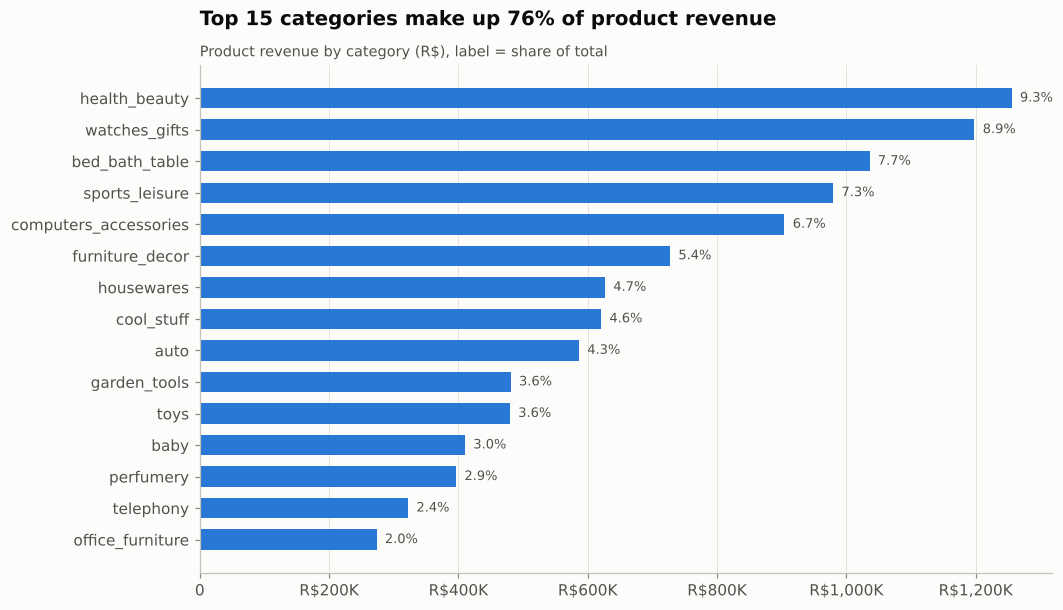

In [6]:
cats = sql('04').sort_values('revenue')
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(cats.category, cats.revenue, color=BLUE, height=0.65)
for y, (rev, share) in enumerate(zip(cats.revenue, cats.revenue_share_pct)):
    ax.text(rev, y, f"  {share:.1f}%", va="center", color=INK_2, fontsize=8.5)
ax.set_title("Top 15 categories make up 76% of product revenue")
subtitle(ax, "Product revenue by category (R$), label = share of total")
money(ax, "x"); ax.grid(axis="y", visible=False)
fig.savefig(IMG / "02_top_categories.png"); plt.show()

In [7]:
health = sql('15')
health[['category','orders','avg_price','freight_to_price_pct','avg_review','late_pct']].head(6)

,category,orders,avg_price,freight_to_price_pct,avg_review,late_pct
0,office_furniture,1254,160.76,25.00,3.52,8.90
1,bed_bath_table,9272,93.44,19.70,3.92,8.40
2,unknown,1392,111.08,15.80,3.94,9.40
3,furniture_decor,6307,87.25,23.80,3.95,8.40
4,telephony,4093,69.95,22.40,3.99,8.30
5,computers_accessories,6530,116.26,16.20,3.99,7.80


**Insights**
- **Health & beauty, watches & gifts, and bed & bath** lead revenue. Watches have the highest
  average price (~R$200), so fewer orders still produce top revenue.
- **Office furniture has the lowest satisfaction (3.52★)** and the heaviest freight burden (25% of
  price). Bulky categories such as furniture and bed & bath consistently score lower, which points
  to a logistics problem rather than a product problem.

## 5. Geography

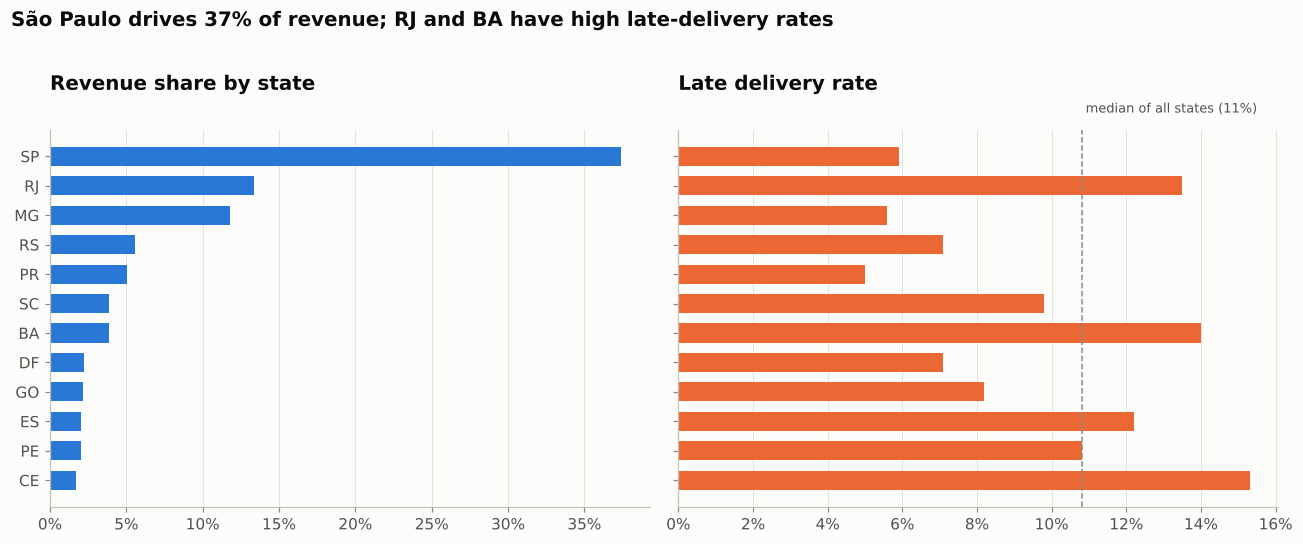

In [8]:
states = sql('05')
top = states.head(12).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(top.state, top.revenue_share_pct, color=BLUE, height=0.65)
axes[0].set_title("Revenue share by state"); axes[0].xaxis.set_major_formatter("{x:.0f}%")
axes[1].barh(top.state, top.late_pct, color=ORANGE, height=0.65)
med = states.late_pct.median()
axes[1].axvline(med, color=MUTED, ls="--", lw=1)
axes[1].text(med, 12.6, f" median of all states ({med:.0f}%)", color=INK_2, fontsize=8.5, va="center")
axes[1].set_title("Late delivery rate"); axes[1].xaxis.set_major_formatter("{x:.0f}%")
for ax in axes: ax.grid(axis="y", visible=False); ax.title.set_fontsize(11)
fig.suptitle("São Paulo drives 37% of revenue; RJ and BA have high late-delivery rates",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(IMG / "03_state_performance.png"); plt.show()

**Insights**
- **SP, RJ and MG generate 62.5% of revenue.** SP orders arrive in 8.7 days on average, versus
  20+ days in the north and northeast.
- **Rio de Janeiro is the #2 market but has a 13.5% late rate (2.3× SP)** and below-average reviews (3.97).
  It is the clearest logistics fix with the biggest revenue at stake.
- Northeastern states (AL 24%, MA 20% late) pay ~2.5× SP's freight and wait ~2.5× longer.

## 6. Delivery performance vs customer satisfaction  ⭐ key finding

delivery_status  orders  pct_of_orders  avg_review  pct_1_star  avg_delivery_days
           Late    7661           8.00        2.57       46.20              31.30
On time / early   88163          92.00        4.29        6.60              10.80


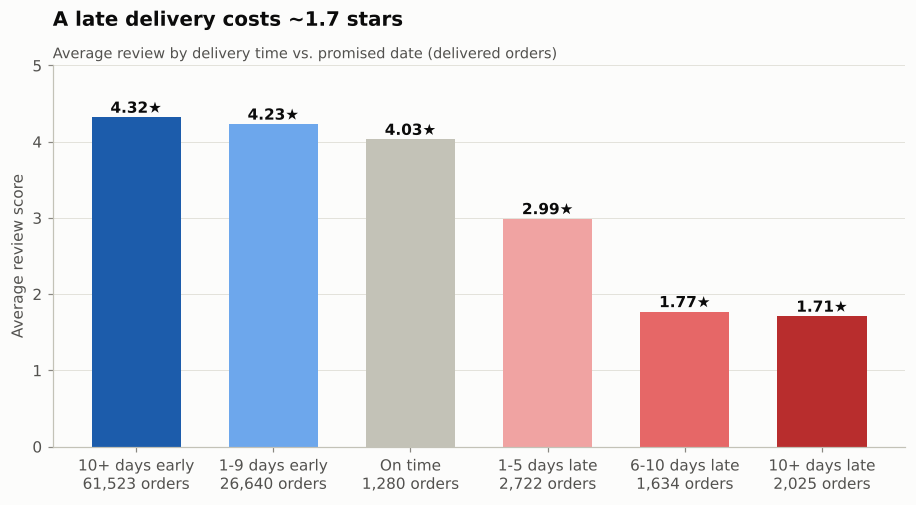

In [9]:
dvr = sql('07')
summary = sql('08')
print(summary.to_string(index=False))

labels = [f"{b.split('. ')[1]}\n{n:,} orders" for b, n in zip(dvr.delivery_bucket, dvr.orders)]
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(labels, dvr.avg_review, color=DIVERGING, width=0.65)
for b, v, n in zip(bars, dvr.avg_review, dvr.orders):
    ax.text(b.get_x() + b.get_width()/2, v + 0.06, f"{v:.2f}★", ha="center", color=INK, fontsize=10, fontweight="bold")
ax.set_ylim(0, 5); ax.set_ylabel("Average review score")
ax.set_title("A late delivery costs ~1.7 stars")
subtitle(ax, "Average review by delivery time vs. promised date (delivered orders)")
ax.grid(axis="x", visible=False)
fig.savefig(IMG / "04_delivery_vs_review.png"); plt.show()

**Insights**
- **8% of orders arrive late, and those orders average 2.57★ vs 4.29★ for on-time orders.**
- **46% of late orders get a 1-star review**, versus 6.6% of on-time orders (7× more).
- Even 1–5 days late drops the score to 2.99★, so customers react to the *broken promise*, not
  just the wait. Orders arriving 10+ days early score highest (4.32★); Olist's conservative
  delivery estimates are working.
- **Delivery reliability is the single biggest driver of satisfaction in this dataset.**

## 7. Seller concentration

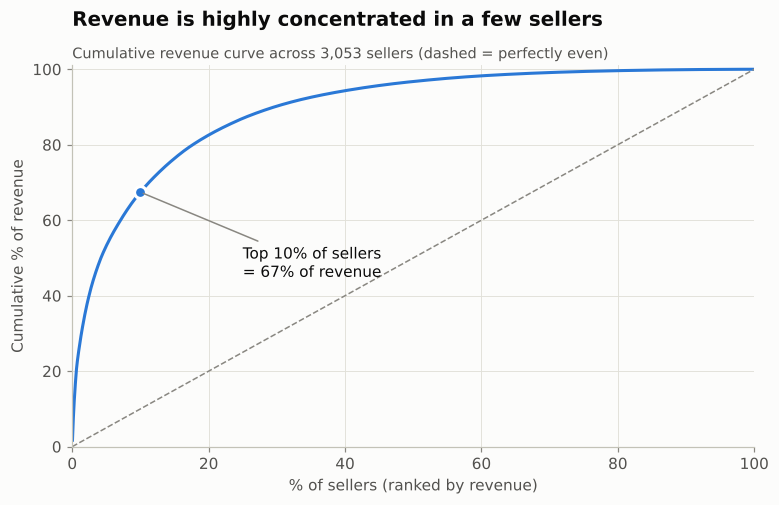

,seller_tier,sellers,revenue,revenue_share_pct
0,1. Top 1%,31,"3,532,697.13",26.20
1,2. Top 1-10%,275,"5,576,039.58",41.30
2,3. Top 10-20%,305,"2,034,669.23",15.10
3,4. Top 20-50%,915,"1,912,915.19",14.20
4,5. Bottom 50%,1527,"438,079.61",3.20


In [10]:
pareto = sql('09')
seller_rev = con.execute("""
    SELECT SUM(oi.price) AS revenue FROM order_items oi JOIN orders o USING (order_id)
    WHERE o.order_status NOT IN ('canceled','unavailable') GROUP BY oi.seller_id ORDER BY 1 DESC
""").df()
cum = seller_rev.revenue.cumsum() / seller_rev.revenue.sum() * 100
x = np.arange(1, len(cum) + 1) / len(cum) * 100
top10 = cum.iloc[int(len(cum) * 0.10) - 1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, cum, color=BLUE)
ax.plot([0, 100], [0, 100], color=MUTED, ls="--", lw=1)
ax.scatter([10], [top10], color=BLUE, s=60, zorder=3, edgecolor="white", linewidth=2)
ax.annotate(f"Top 10% of sellers\n= {top10:.0f}% of revenue", (10, top10), xytext=(25, 45),
            textcoords="data", color=INK, fontsize=10, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_xlabel("% of sellers (ranked by revenue)"); ax.set_ylabel("Cumulative % of revenue")
ax.set_title("Revenue is highly concentrated in a few sellers")
subtitle(ax, f"Cumulative revenue curve across {len(cum):,} sellers (dashed = perfectly even)")
ax.set_xlim(0, 100); ax.set_ylim(0, 101)
fig.savefig(IMG / "05_seller_pareto.png"); plt.show()
pareto

In [11]:
sql('10').query("seller_flag == 'Needs attention'")

,revenue_rank,seller_id,seller_state,orders,revenue,avg_review,late_pct,seller_flag
4,5,7c67e1448b00f6e969d365cea6b010ab,SP,973,"186,570.05",3.35,9.60,Needs attention
21,22,f7ba60f8c3f99e7ee4042fdef03b70c4,SP,218,"68,070.00",4.22,16.60,Needs attention


**Insights**
- **The top 10% of sellers (~306) generate 67.5% of revenue**, and the top 1% (31 sellers) generate 26%.
- The bottom 50% of sellers contribute only 3.2%.
- Losing a handful of top sellers would be a real risk. Among them, the **#5 seller (R$187K) averages
  only 3.35★**, a high-value account that needs a quality intervention.

## 8. Customer retention

customer_type  customers  pct_customers  pct_revenue  avg_lifetime_spend
      1 order      92102          96.96        94.34              161.22
     2 orders       2652           2.79         4.91              291.12
    3+ orders        236           0.25         0.75              502.08


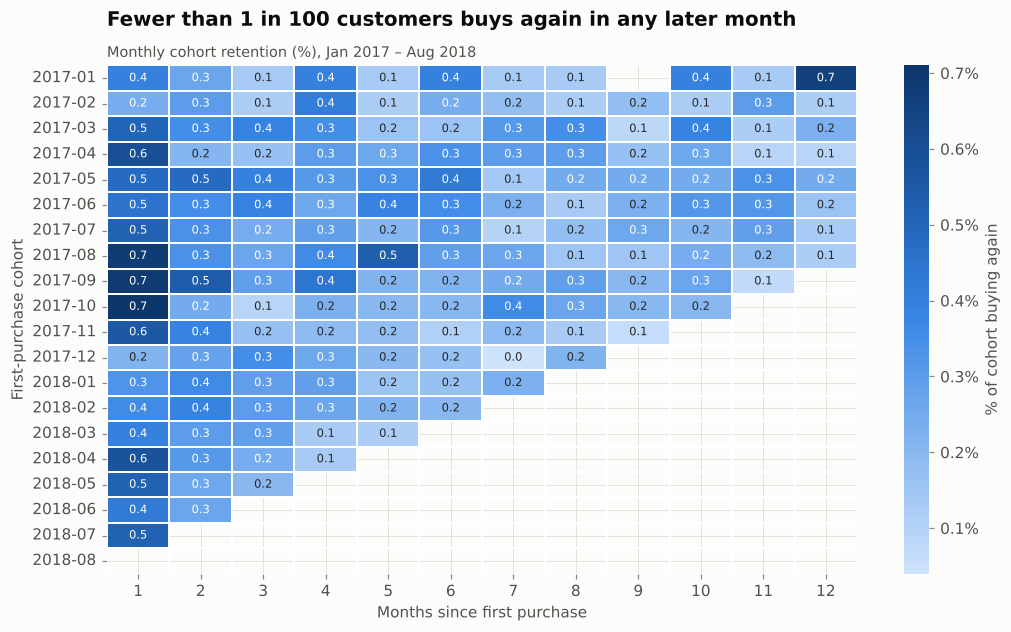

In [12]:
repeat = sql('11')
print(repeat.to_string(index=False))

cohort = sql('12')
pivot = (cohort.assign(cohort=cohort.cohort_month.dt.strftime('%Y-%m'))
               .pivot(index='cohort', columns='month_number', values='retention_pct'))
pivot = pivot.loc[:, 1:12]
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(pivot, cmap=sns.blend_palette(SEQ_BLUE, as_cmap=True), annot=True, fmt=".1f",
            annot_kws={"size": 7.5}, cbar_kws={"label": "% of cohort buying again", "format": "%.1f%%"},
            linewidths=1, linecolor="white", ax=ax)
ax.set_xlabel("Months since first purchase"); ax.set_ylabel("First-purchase cohort")
ax.set_title("Fewer than 1 in 100 customers buys again in any later month")
subtitle(ax, "Monthly cohort retention (%), Jan 2017 – Aug 2018")
fig.savefig(IMG / "06_cohort_retention.png"); plt.show()

**Insights**
- **97% of customers order only once.** The 3% who return have about 2× the lifetime spend.
- Month-1 retention never exceeds 0.7% for any cohort, with no improvement over time.
- This explains the 2018 plateau: **the business acquires customers but doesn't keep them.**
  Moving repeat rate from 3% to 6% would add roughly R$350K a year (~73K customers/yr × 3 pts × R$161 avg order).

## 9. RFM customer segmentation

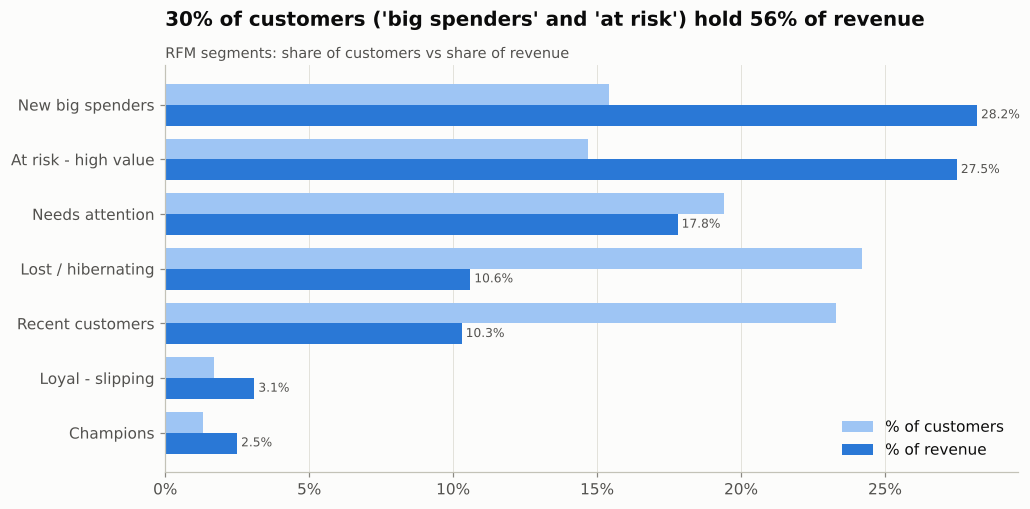

,segment,customers,pct_customers,revenue,pct_revenue,avg_recency_days,avg_orders,avg_spend
0,New big spenders,14646,15.40,"4,439,187.99",28.20,141.00,1.00,303.10
1,At risk - high value,13985,14.70,"4,324,245.26",27.50,444.00,1.00,309.21
2,Needs attention,18388,19.40,"2,796,772.45",17.80,269.00,1.00,152.10
3,Lost / hibernating,22974,24.20,"1,672,481.13",10.60,445.00,1.00,72.80
4,Recent customers,22108,23.30,"1,615,916.06",10.30,139.00,1.00,73.09
5,Loyal - slipping,1646,1.70,"491,619.35",3.10,370.00,2.08,298.68
6,Champions,1242,1.30,"398,914.77",2.50,138.00,2.16,321.19


In [13]:
rfm = sql('13')
order = rfm.sort_values('pct_revenue')
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(order)); h = 0.38
ax.barh(y + h/2, order.pct_customers, h, color="#9ec5f4", label="% of customers")
ax.barh(y - h/2, order.pct_revenue, h, color=BLUE, label="% of revenue")
ax.set_yticks(y, order.segment); ax.xaxis.set_major_formatter("{x:.0f}%")
for i, (c, r) in enumerate(zip(order.pct_customers, order.pct_revenue)):
    ax.text(r, i - h/2, f" {r:.1f}%", va="center", fontsize=8, color=INK_2)
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("30% of customers ('big spenders' and 'at risk') hold 56% of revenue")
subtitle(ax, "RFM segments: share of customers vs share of revenue")
fig.savefig(IMG / "07_rfm_segments.png"); plt.show()
rfm

**Insights**
- **"At risk – high value" (14% of customers, 27.5% of revenue)** spent ~R$309 each but haven't
  bought in ~15 months. They are the top target for a win-back campaign.
- **"New big spenders" (15%, 28% of revenue)** are recent, high-value first-time buyers. Converting them
  to a second order is the biggest retention opportunity.
- Champions (repeat + recent) are only 1.3% of customers; a loyalty programme has a lot of room to grow.

## 10. When do customers shop?

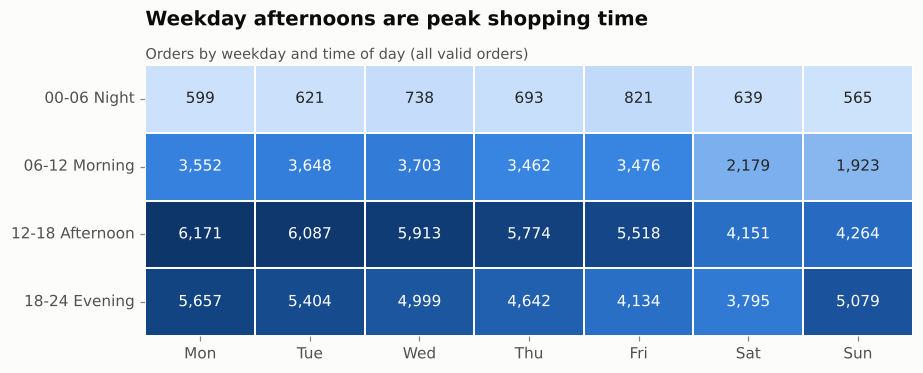

In [14]:
timing = sql('14')
heat = timing.pivot_table(index='time_of_day', columns='weekday_num', values='orders')
heat.columns = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
fig, ax = plt.subplots(figsize=(9, 3.2))
sns.heatmap(heat, cmap=sns.blend_palette(SEQ_BLUE, as_cmap=True), annot=True, fmt=",.0f",
            linewidths=1, linecolor="white", cbar=False, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title("Weekday afternoons are peak shopping time")
subtitle(ax, "Orders by weekday and time of day (all valid orders)")
fig.savefig(IMG / "08_purchase_timing.png"); plt.show()

**Insight:** orders peak **Monday–Tuesday, 12:00–18:00**, and weekends are ~30% quieter. Schedule
email campaigns and promotions for Monday late morning to catch the peak.

## 11. Summary & recommendations

| # | Finding | Recommendation | Expected impact |
|---|---------|----------------|-----------------|
| 1 | Late orders (8%) score **2.57★ vs 4.29★**; 46% get 1 star | Set SLA alerts for orders at risk of missing the estimate; penalise/coach chronically late sellers; prioritise RJ & northeast carriers | Halving late deliveries would lift the average rating from 4.12 to ~4.19 and cut 1-star reviews by ~16% |
| 2 | **97% of customers buy once**; growth flat in 2018 | Post-purchase email/coupon flow targeting the 2nd order within 30–60 days | Each +1 pt of repeat rate ≈ R$118K/yr |
| 3 | "At risk – high value" = 27.5% of revenue | Win-back campaign with personalised category offers | Recover part of R$4.3M historical spend |
| 4 | Top 10% sellers = 67.5% of revenue; some have low ratings | Key-account programme for top sellers, quality reviews for flagged ones | Lower concentration risk |
| 5 | RJ = #2 market with 2.3× SP's late rate | Regional fulfilment partner / better carrier for RJ | Protect R$2M market |
| 6 | Black Friday = 6.3× normal day | Plan inventory, carrier capacity and campaigns for Nov peak | Avoid peak-season delays that hurt reviews |